# Network Intrusion Detection using Machine Learning

This project processes the CICIDS2017 dataset, performs feature selection,
and trains a Random Forest classifier to detect malicious network traffic.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
files = [
    r"C:\Users\rafat\Downloads\archive\Monday-WorkingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Tuesday-WorkingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Wednesday-workingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Morning.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
]

# Combine all files
df = pd.concat(
    [pd.read_csv(f, low_memory=False) for f in files],
    ignore_index=True
)

print("Dataset shape:", df.shape)

Dataset shape: (2830743, 79)


In [3]:
# Replace inf values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Create binary label
df['Binary_Label'] = (df[' Label'].str.strip().str.lower() != 'benign').astype(int)

# Remove original label
df.drop(columns=[' Label'], inplace=True)

print("Original number of columns:", df.shape[1])

# Remove constant columns
constant_cols = [col for col in df.columns if df[col].nunique() == 1]

df.drop(columns=constant_cols, inplace=True)

print("Columns removed:", len(constant_cols))
print("Remaining columns:", df.shape[1])

# Save dataset
df.to_csv("final_work.csv", index=False)

print("Dataset saved as final_work.csv")

Original number of columns: 79
Columns removed: 8
Remaining columns: 71
Dataset saved as final_work.csv


In [4]:
df = pd.read_csv("final_work.csv")

# Drop non-numeric columns
non_numeric_cols = [' Source IP', ' Destination Port', ' Timestamp']
df.drop(columns=[c for c in non_numeric_cols if c in df.columns], inplace=True)

# Separate target
y = df['Binary_Label']
df.drop(columns=['Binary_Label'], inplace=True)

print("Original number of features:", df.shape[1])

# Correlation matrix
corr_matrix = df.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.90
to_drop = [column for column in upper.columns if any(upper[column] > threshold)]

print("Features removed:", len(to_drop))

df_reduced = df.drop(columns=to_drop)

print("Remaining features:", df_reduced.shape[1])

df_reduced['Binary_Label'] = y

df_reduced.to_csv("work_reduced.csv", index=False)

print("New dataset saved as work_reduced.csv")

Original number of features: 69
Features removed: 31
Remaining features: 38
New dataset saved as work_reduced.csv


In [5]:
df = pd.read_csv("work_reduced.csv")

X = df.drop(columns=['Binary_Label'])
y = df['Binary_Label']

print("Total features used for training:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

Total features used for training: 38
Training samples: 2262300
Testing samples: 565576


Accuracy: 0.9990575979178749

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    454265
           1       1.00      1.00      1.00    111311

    accuracy                           1.00    565576
   macro avg       1.00      1.00      1.00    565576
weighted avg       1.00      1.00      1.00    565576



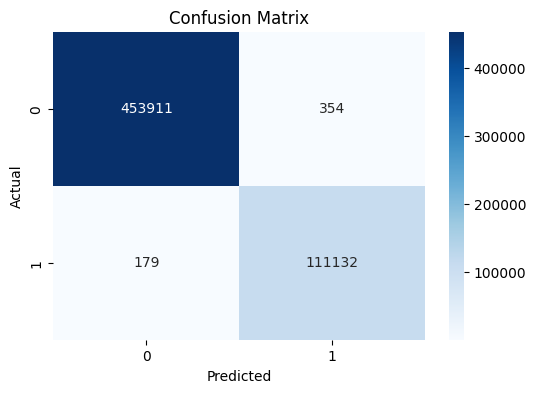

In [6]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [7]:
import joblib

joblib.dump(rf, "rf_model.pkl")

print("Model saved as rf_model.pkl")

Model saved as rf_model.pkl
